# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot scatter plot of precipiation and wave heights to see compound impacts at each of the four villages

**Notebook by Alice DuVivier - August 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick
import math

## Set villages and node of choice

In [2]:
# set node info - '2a'
village_node = '2a'

In [3]:
# set paired lists name and node of interest
village_names = ['Nome','Savoonga','Shishmaref','Unalakleet']
village_lats =  [64.501, 63.694, 66.257, 63.879]
village_lons =  [-165.406, -170.479, -166.072, -160.790]

# set xloc and yloc values - determined from another notebook finding nearest atmospheric point that is over mostly ocean
village_xlocs_atm = [57,55,65,55]
village_ylocs_atm = [98,78,95,115]

village_xlocs_ice = [261,238,289,263]
village_ylocs_ice = [270,234,254,310]

nvillages  = len(village_names)
print(nvillages)

4


## Load data
- not identical to training data so we can see larger area patterns

In [4]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_single_node/'

In [5]:
# choose data - load meridional wind next
var_in = 'aice_d'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
sic = data

In [6]:
# set ocean/ice lat/lons - need to read in a separate grid file
dir_in_grid = '/glade/u/home/duvivier/masks/'
file_in = 'POP_tx0.1v3_grid.nc'
ds_grid = xr.open_dataset(dir_in_grid+file_in, decode_times=False)

# rename coordinates to those used in ice files
ds_grid = ds_grid.rename({'nlat': 'nj', 'nlon': 'ni'})
# clip global data to just Alaska
ds_grid_sub = ds_grid.isel(nj=slice(1700,2250)).isel(ni=slice(2700,3300))

lat2d = ds_grid_sub.TLAT
lon2d = ds_grid_sub.TLONG
land = ds_grid_sub.KMT

# need to convert the longitude to 0-360 instead of -180 to 180
lon2d = lon2d.where(lon2d >0, lon2d+360)

In [7]:
# choose data - load 10m wind
var_in = 'U10'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
u10 = data

In [8]:
# choose data - load zonal wind first
var_in = 'PRECT'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
precip = data

In [9]:
# set atmosphere lat/lons
lat1d = ds.lat
lon1d = ds.lon

## Break Data into decades

In [10]:
# choose subset of decades to do initial analysis
decades = [1950,2000,2050]
decades_str = ['1950','2000','2050']

In [11]:
# data for each decade in subset of decades
mask_1950 = ds.time.where(ds.decades == 1950)
u10_1950 = u10.where(mask_1950 >= 0, drop=True)
precip_1950 = precip.where(mask_1950 >= 0, drop=True)
sic_1950 = sic.where(mask_1950 >= 0, drop=True)
print('number of times in 1950:'+str(len(u10_1950.time)))

mask_2000 = ds.time.where(ds.decades == 2000)
u10_2000 = u10.where(mask_2000 >= 0, drop=True)
precip_2000 = precip.where(mask_2000 >= 0, drop=True)
sic_2000 = sic.where(mask_2000 >= 0, drop=True)
print('number of times in 2000:'+str(len(u10_2000.time)))

mask_2050 = ds.time.where(ds.decades == 2050)
u10_2050 = u10.where(mask_2050 >= 0, drop=True)
precip_2050 = precip.where(mask_2050 >= 0, drop=True)
sic_2050 = sic.where(mask_2050 >= 0, drop=True)
print('number of times in 2050:'+str(len(u10_2050.time)))

number of times in 1950:198
number of times in 2000:270
number of times in 2050:303


## Get data at villages
- need to loop through each village for each decade

### Atmosphere - U10

In [12]:
## 1950
data_in = u10_1950

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
u10_villages_1950 = xr.DataArray(data_array,dims=('villages','times'))
u10_villages_1950['villages'] = village_names

In [13]:
## 2000
data_in = u10_2000

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
u10_villages_2000 = xr.DataArray(data_array,dims=('villages','times'))
u10_villages_2000['villages'] = village_names

In [14]:
## 2050
data_in = u10_2050

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
u10_villages_2050 = xr.DataArray(data_array,dims=('villages','times'))
u10_villages_2050['villages'] = village_names

### Atmosphere - PRECIP

In [15]:
## 1950
data_in = precip_1950

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
precip_villages_1950 = xr.DataArray(data_array,dims=('villages','times'))
precip_villages_1950['villages'] = village_names

In [16]:
## 2000
data_in = precip_2000

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
precip_villages_2000 = xr.DataArray(data_array,dims=('villages','times'))
precip_villages_2000['villages'] = village_names

In [17]:
## 2050
data_in = precip_2050

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
precip_villages_2050 = xr.DataArray(data_array,dims=('villages','times'))
precip_villages_2050['villages'] = village_names

### Sea Ice - SIC

In [18]:
## 1950
data_in = sic_1950

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_ice[index]
    yloc = village_ylocs_ice[index]
    # keep data at this grid point only
    temp = data_in.isel(nj=slice(xloc,xloc+1),ni=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(nj=0,ni=0)

# convert the numpy arrays to xarrays for easier plotting
sic_villages_1950 = xr.DataArray(data_array,dims=('villages','times'))
sic_villages_1950['villages'] = village_names

In [19]:
## 2000
data_in = sic_2000

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_ice[index]
    yloc = village_ylocs_ice[index]
    # keep data at this grid point only
    temp = data_in.isel(nj=slice(xloc,xloc+1),ni=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(nj=0,ni=0)

# convert the numpy arrays to xarrays for easier plotting
sic_villages_2000 = xr.DataArray(data_array,dims=('villages','times'))
sic_villages_2000['villages'] = village_names

In [20]:
## 2050
data_in = sic_2050

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_ice[index]
    yloc = village_ylocs_ice[index]
    # keep data at this grid point only
    temp = data_in.isel(nj=slice(xloc,xloc+1),ni=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(nj=0,ni=0)

# convert the numpy arrays to xarrays for easier plotting
sic_villages_2050 = xr.DataArray(data_array,dims=('villages','times'))
sic_villages_2050['villages'] = village_names

## Calculate Significant Wave Height
- Use empirical formulas from USGS and NIWA to calculate wave height and period for fetch limited fairly shallow sea. 
- Depends on fetch, gravity, and 10m wind speed
- Tested a couple options for fetch (f) - 100,000m (100km) and 1,000,000m (1000km) - and the wave size IS very sensitive to this. Wave are ~5-10m with shorter distance and ~10-25m with longer distance. Based on the collaborators' comments that the SW winds blow for 1000s of km from SW Bering Sea, we will go with the larger value to be less conservative on what the biggest waves are.
- Then we use sea ice concentration to attenuate waves. This is a very complicated situation with many ways this can be done and information we may not have. Therefore, we will do a very simple scaling where we attenuate the waves by concentration. For SIC 0%, there is 0% attenuation, for SIC 50% there is 50% attenuation, for SIC 100% there is 100% attenuation. etc. We recognize this is very simplified from reality.

In [21]:
# set constants
# gravity
g = 9.8  #m/s2

# set fetch (f) - 1,000,000m (1000km) - the result is very sensitive, but used big value because of comments from collaborators
f = 1000000  #m

In [22]:
# 1950 - with attenuation
utmp = u10_villages_1950
sitmp = sic_villages_1950/100
ustar_tmp = (0.001*(1.1+(0.35*utmp))*(utmp**2))**0.5
hs_tmp = 0.0413 * (((ustar_tmp**2)*f)/g)**0.5

# sea ice attenuation component
hs_villages_1950 = hs_tmp*(1-sitmp)

In [23]:
# 2000 - with attenuation
utmp = u10_villages_2000
sitmp = sic_villages_2000/100
ustar_tmp = (0.001*(1.1+(0.35*utmp))*(utmp**2))**0.5
hs_tmp = 0.0413 * (((ustar_tmp**2)*f)/g)**0.5

# sea ice attenuation component
hs_villages_2000 = hs_tmp*(1-sitmp)

In [24]:
# 2050 - with attenuation
utmp = u10_villages_2050
sitmp = sic_villages_2050/100
ustar_tmp = (0.001*(1.1+(0.35*utmp))*(utmp**2))**0.5
hs_tmp = 0.0413 * (((ustar_tmp**2)*f)/g)**0.5

# sea ice attenuation component
hs_villages_2050 = hs_tmp*(1-sitmp)

## Count instances above some thresholds
- Using some absolute thresholds rather than some fraction above decadeal mean since it is the extreme events that matter. There could be a debate of if the threshold should shift with changing mean state, but a 30mph event will impact people whether it's above the normal or not. People impacts are absolute, not relative.
- This plot is to find **COMPOUND** impacts, so we want to find instances where it is above BOTH the significant wave height and precipitation threshold

### Thresholds

Significant wave height
- **6.1m = 20ft**
- Note that these are **SIGNIFICANT WAVE HEIGHT**, or height of top 1/3 of waves. So there are higher waves. Also, this is from an empirical relationship and assuming ice impacts. So, it's not a fully developed wave field.
- Elevations of the airports of the villages are: Nome - 40ft; Unalakleet - 27ft; Shishmaref - 14ft; Savoonga - 59ft.

Precipitation
- **1.27 cm/day = 0.5 in/day**

In [25]:
# set thresholds
thresh_hs = 6.1
thresh_precip = 1.27

In [26]:
## 1950
data_1 = hs_villages_1950
data_2 = precip_villages_1950

# preallocate array
ntime = len(data_1.times)
data_array = np.zeros([nvillages])

# loop through each village to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub_1 = data_1.isel(villages=index)
    data_sub_2 = data_2.isel(villages=index)
    # get data that is above the threshold
    sub1 = data_sub_2.where((data_sub_1 > thresh_hs),drop=True)
    sub2 = sub1.where((sub1 > thresh_precip),drop=True)
    count=len(sub2) 
    # save raw number of counts
    data_array[index] = count

# convert the numpy arrays to xarrays for easier plotting
count_compound_villages_1950 = xr.DataArray(data_array,dims=('villages'))
count_compound_villages_1950['villages'] = village_names

In [27]:
## 2000
data_1 = hs_villages_2000
data_2 = precip_villages_2000

# preallocate array
ntime = len(data_1.times)
data_array = np.zeros([nvillages])

# loop through each village to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub_1 = data_1.isel(villages=index)
    data_sub_2 = data_2.isel(villages=index)
    # get data that is above the threshold
    sub1 = data_sub_2.where((data_sub_1 > thresh_hs),drop=True)
    sub2 = sub1.where((sub1 > thresh_precip),drop=True)
    count=len(sub2) 
    # save raw number of counts
    data_array[index] = count

# convert the numpy arrays to xarrays for easier plotting
count_compound_villages_2000 = xr.DataArray(data_array,dims=('villages'))
count_compound_villages_2000['villages'] = village_names

In [28]:
## 2050
data_1 = hs_villages_2050
data_2 = precip_villages_2050

# preallocate array
ntime = len(data_1.times)
data_array = np.zeros([nvillages])

# loop through each village to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub_1 = data_1.isel(villages=index)
    data_sub_2 = data_2.isel(villages=index)
    # get data that is above the threshold
    sub1 = data_sub_2.where((data_sub_1 > thresh_hs),drop=True)
    sub2 = sub1.where((sub1 > thresh_precip),drop=True)
    count=len(sub2) 
    # save raw number of counts
    data_array[index] = count

# convert the numpy arrays to xarrays for easier plotting
count_compound_villages_2050 = xr.DataArray(data_array,dims=('villages'))
count_compound_villages_2050['villages'] = village_names

In [29]:
# print these differences
print('Counts with extreme compound impacts')
print('1950')
print(count_compound_villages_1950.values)
print('2000')
print(count_compound_villages_2000.values)
print('2050')
print(count_compound_villages_2050.values)
print(village_names)

Counts with extreme compound impacts
1950
[32.  2.  3. 17.]
2000
[48. 10.  5. 31.]
2050
[59. 11.  8. 36.]
['Nome', 'Savoonga', 'Shishmaref', 'Unalakleet']


## Plot wind and wave height distributions villages

In [30]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'

In [31]:
# set colors 
ch1 = 'blue' 
ch2 = 'gold' #'mediumorchid'
ch3 = 'red'

### Plot scatter plot distributions

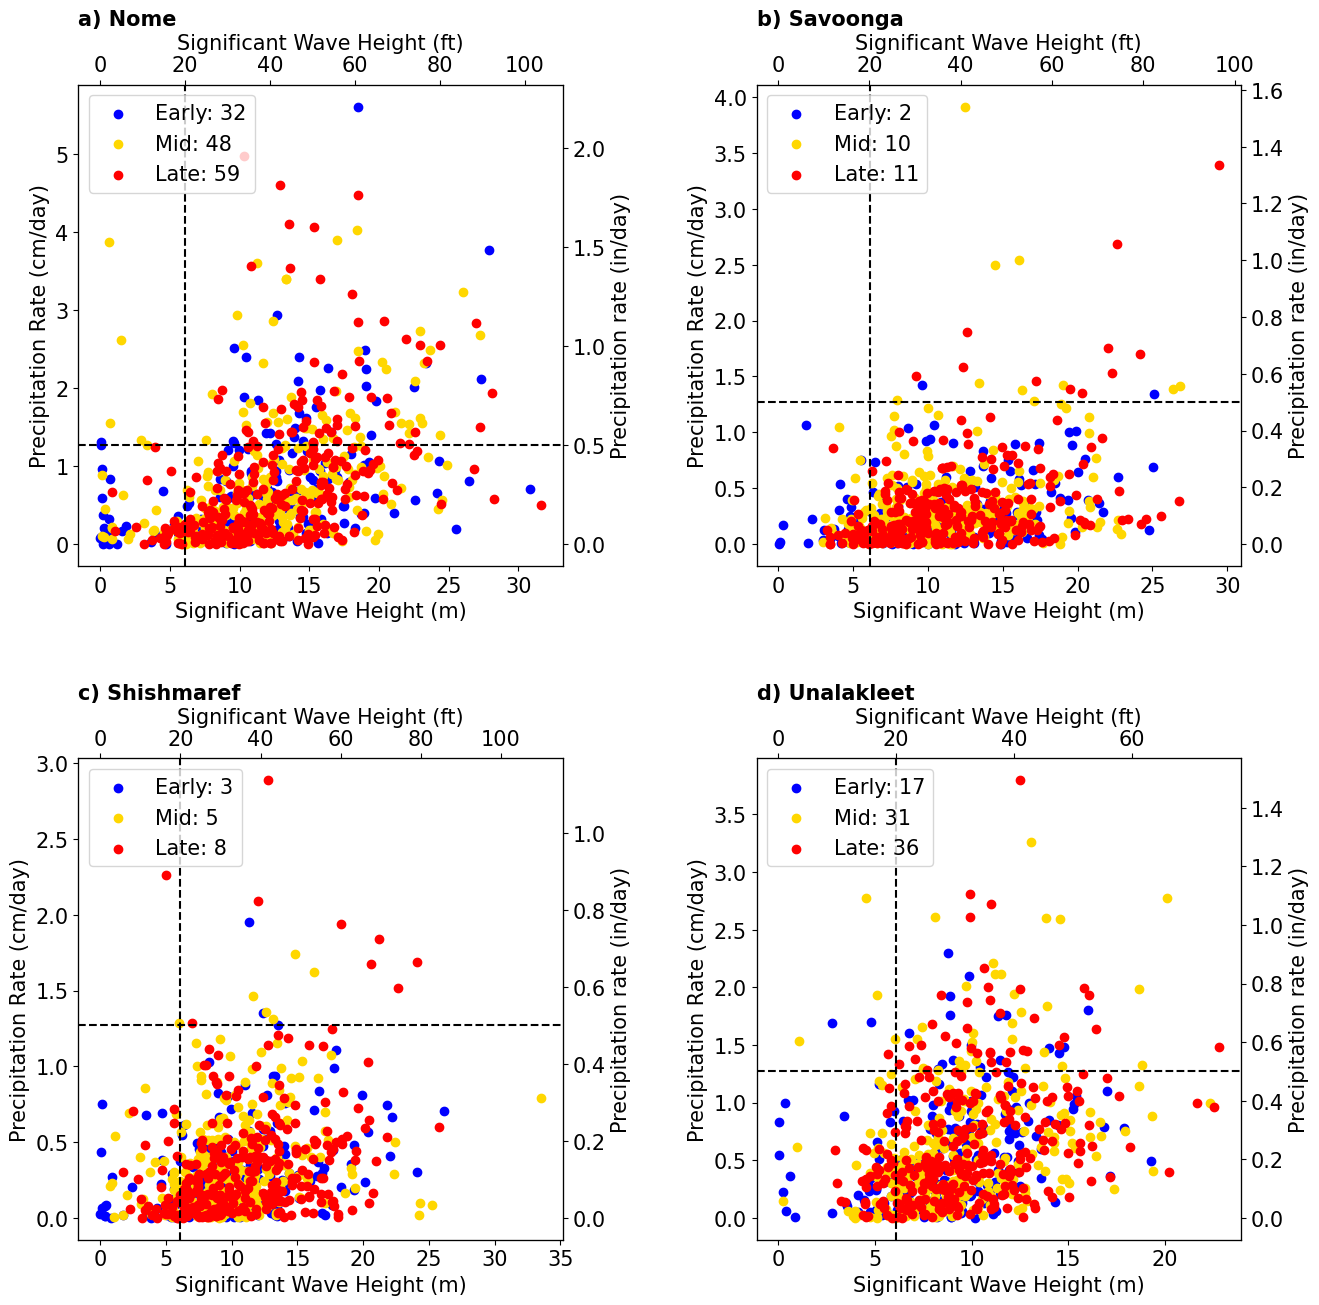

In [32]:
# U10 - create figure
fout = 'figure_7_node_'+village_node+'_compound_impacts_scatter_decadal'

fig = plt.figure(figsize=(15,15))

# Make subplot - note it's nrow x ncol x index (starting upper left) - 3 rows x 2 columns
### Plot 1  - Box Plot ###
ax = fig.add_subplot(2,2,1)
n=0
# scatter plot
scatter = ax.scatter(hs_villages_1950.isel(villages=n),precip_villages_1950.isel(villages=n),color=ch1,label='Early: '+str(int(count_compound_villages_1950.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2000.isel(villages=n),precip_villages_2000.isel(villages=n),color=ch2,label='Mid: '+str(int(count_compound_villages_2000.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2050.isel(villages=n),precip_villages_2050.isel(villages=n),color=ch3,label='Late: '+str(int(count_compound_villages_2050.isel(villages=n).values)))
# modify plot
plt.axhline(y=thresh_precip, color='black', linestyle='--')
plt.axvline(x=thresh_hs, color='black', linestyle='--')
plt.title('a) '+village_names[n],loc='left',fontsize=15,fontweight='bold')
plt.xlabel('Significant Wave Height (m)',fontsize=15)
plt.xticks(fontsize=15)
plt.ylabel('Precipitation Rate (cm/day)',fontsize=15)
plt.yticks(fontsize=15)
# --- secondary y-axis in in/day ---
ax2 = ax.twinx()
cm_to_in = 0.393701
ymin, ymax = ax.get_ylim()
ax2.set_ylim(ymin * cm_to_in, ymax * cm_to_in)
ax2.set_ylabel('Precipitation rate (in/day)', fontsize=15)
ax2.tick_params(axis='y', labelsize=15)
# --- secondary x-axis in feet ---
ax3 = ax.twiny()
m_to_ft = 3.28084
xmin, xmax = ax.get_xlim()
ax3.set_xlim(xmin * m_to_ft, xmax * m_to_ft)
ax3.set_xlabel('Significant Wave Height (ft)', fontsize=15)
ax3.tick_params(axis='x', labelsize=15)
# add legend
ax.legend(fontsize=15, loc='upper left')

### Plot 2  - Box Plot ###
ax = fig.add_subplot(2,2,2)
n=1
# scatter plot
scatter = ax.scatter(hs_villages_1950.isel(villages=n),precip_villages_1950.isel(villages=n),color=ch1,label='Early: '+str(int(count_compound_villages_1950.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2000.isel(villages=n),precip_villages_2000.isel(villages=n),color=ch2,label='Mid: '+str(int(count_compound_villages_2000.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2050.isel(villages=n),precip_villages_2050.isel(villages=n),color=ch3,label='Late: '+str(int(count_compound_villages_2050.isel(villages=n).values)))
# modify plot
plt.axhline(y=thresh_precip, color='black', linestyle='--')
plt.axvline(x=thresh_hs, color='black', linestyle='--')
plt.title('b) '+village_names[n],loc='left',fontsize=15,fontweight='bold')
plt.xlabel('Significant Wave Height (m)',fontsize=15)
plt.xticks(fontsize=15)
plt.ylabel('Precipitation Rate (cm/day)',fontsize=15)
plt.yticks(fontsize=15)
# --- secondary y-axis in in/day ---
ax2 = ax.twinx()
cm_to_in = 0.393701
ymin, ymax = ax.get_ylim()
ax2.set_ylim(ymin * cm_to_in, ymax * cm_to_in)
ax2.set_ylabel('Precipitation rate (in/day)', fontsize=15)
ax2.tick_params(axis='y', labelsize=15)
# --- secondary x-axis in feet ---
ax3 = ax.twiny()
m_to_ft = 3.28084
xmin, xmax = ax.get_xlim()
ax3.set_xlim(xmin * m_to_ft, xmax * m_to_ft)
ax3.set_xlabel('Significant Wave Height (ft)', fontsize=15)
ax3.tick_params(axis='x', labelsize=15)
# add legend
ax.legend(fontsize=15, loc='upper left')

### Plot 3  - Box Plot ###
ax = fig.add_subplot(2,2,3)
n=2
# scatter plot
scatter = ax.scatter(hs_villages_1950.isel(villages=n),precip_villages_1950.isel(villages=n),color=ch1,label='Early: '+str(int(count_compound_villages_1950.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2000.isel(villages=n),precip_villages_2000.isel(villages=n),color=ch2,label='Mid: '+str(int(count_compound_villages_2000.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2050.isel(villages=n),precip_villages_2050.isel(villages=n),color=ch3,label='Late: '+str(int(count_compound_villages_2050.isel(villages=n).values)))
# modify plot
plt.axhline(y=thresh_precip, color='black', linestyle='--')
plt.axvline(x=thresh_hs, color='black', linestyle='--')
plt.title('c) '+village_names[n],loc='left',fontsize=15,fontweight='bold')
plt.xlabel('Significant Wave Height (m)',fontsize=15)
plt.xticks(fontsize=15)
plt.ylabel('Precipitation Rate (cm/day)',fontsize=15)
plt.yticks(fontsize=15)
# --- secondary y-axis in in/day ---
ax2 = ax.twinx()
cm_to_in = 0.393701
ymin, ymax = ax.get_ylim()
ax2.set_ylim(ymin * cm_to_in, ymax * cm_to_in)
ax2.set_ylabel('Precipitation rate (in/day)', fontsize=15)
ax2.tick_params(axis='y', labelsize=15)
# --- secondary x-axis in feet ---
ax3 = ax.twiny()
m_to_ft = 3.28084
xmin, xmax = ax.get_xlim()
ax3.set_xlim(xmin * m_to_ft, xmax * m_to_ft)
ax3.set_xlabel('Significant Wave Height (ft)', fontsize=15)
ax3.tick_params(axis='x', labelsize=15)
# add legend
ax.legend(fontsize=15, loc='upper left')

### Plot 4  - Box Plot ###
ax = fig.add_subplot(2,2,4)
n=3
# scatter plot
scatter = ax.scatter(hs_villages_1950.isel(villages=n),precip_villages_1950.isel(villages=n),color=ch1,label='Early: '+str(int(count_compound_villages_1950.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2000.isel(villages=n),precip_villages_2000.isel(villages=n),color=ch2,label='Mid: '+str(int(count_compound_villages_2000.isel(villages=n).values)))
scatter = ax.scatter(hs_villages_2050.isel(villages=n),precip_villages_2050.isel(villages=n),color=ch3,label='Late: '+str(int(count_compound_villages_2050.isel(villages=n).values)))
# modify plot
plt.axhline(y=thresh_precip, color='black', linestyle='--')
plt.axvline(x=thresh_hs, color='black', linestyle='--')
plt.title('d) '+village_names[n],loc='left',fontsize=15,fontweight='bold')
plt.xlabel('Significant Wave Height (m)',fontsize=15)
plt.xticks(fontsize=15)
plt.ylabel('Precipitation Rate (cm/day)',fontsize=15)
plt.yticks(fontsize=15)
# --- secondary y-axis in in/day ---
ax2 = ax.twinx()
cm_to_in = 0.393701
ymin, ymax = ax.get_ylim()
ax2.set_ylim(ymin * cm_to_in, ymax * cm_to_in)
ax2.set_ylabel('Precipitation rate (in/day)', fontsize=15)
ax2.tick_params(axis='y', labelsize=15)
# --- secondary x-axis in feet ---
ax3 = ax.twiny()
m_to_ft = 3.28084
xmin, xmax = ax.get_xlim()
ax3.set_xlim(xmin * m_to_ft, xmax * m_to_ft)
ax3.set_xlabel('Significant Wave Height (ft)', fontsize=15)
ax3.tick_params(axis='x', labelsize=15)
# add legend
ax.legend(fontsize=15, loc='upper left')

# Finalize figure and save
fig.subplots_adjust(wspace=0.4,hspace=0.4)
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)